# Chiral quasi-Bound State in the Continuum (qBIC) & Uniform Optical Chirality Enhancement

This notebook demonstrates the simulation of an **all-dielectric chiral quasi-Bound State in the Continuum (qBIC) metasurface** using EMUstack and Netgen.

### Scientific Literature Context
- **All-Dielectric Quasi-BICs**: Ideal symmetry-protected BICs possess infinite theoretical quality factors ($Q \to \infty$) and zero radiation leakage (*Koshelev et al., Science* 367, 288, 2020; *Overvig et al., Phys. Rev. Lett.* 126, 073001, 2021). By introducing an in-plane geometric asymmetry parameter $\alpha$, the symmetry is broken, converting the dark BIC into a high-$Q$ **quasi-BIC** with an accessible Fano resonance.
- **Uniform (Single-Sign) Optical Chirality Enhancement**: In conventional plasmonic chiral nanostructures, the local optical chirality density $C(\mathbf{r}) = -\frac{k_0}{2} \operatorname{Im}(\mathbf{E}^* \cdot \mathbf{H})$ frequently oscillates in sign across subwavelength distances, leading to mutual cancellation when integrated over an analyte volume. In contrast, all-dielectric qBIC metasurfaces excite overlapping high-$Q$ electric and magnetic multipoles that produce **large and spatially uniform (single-sign) superchiral fields** across the accessible hotspot gaps (*Hu, Lawrence, & Dionne, ACS Photonics* 7, 36, 2020; *Solomon et al., ACS Photonics* 6, 43, 2019).
- **Chiroptical Sensing Objective**: For enantioselective biosensing, we do not require giant far-field circular dichroism (which can introduce baseline optical artifacts). Rather, the primary objective is to obtain a sharp high-$Q$ resonance with a **uniform, homochiral optical chirality enhancement** $\hat{C} = C / |C_{\mathrm{CPL}}|$ across the unit cell.
- **Adaptive Sampling with Curvature Loss**: We employ `adaptive.Learner1D` with `curvature_loss_function` to adaptively sample the spectrum until reaching a target loss of $0.005$, ensuring optimal point density in regions of high spectral curvature.

In [7]:
import os
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from adaptive import Learner1D
from adaptive.learner.learner1D import curvature_loss_function

# Add EMUstack backend and mesh directories to path
current_dir = os.path.dirname(os.path.abspath('__file__'))
backend_dir = os.path.abspath(os.path.join(current_dir, '../backend'))
mesh_dir = os.path.join(backend_dir, 'data', 'meshes')
for p in (current_dir, backend_dir, mesh_dir):
    if p not in sys.path:
        sys.path.insert(0, p)

import objects
import materials
import plotting
from stack import Stack
import chiral_qbic_template
%matplotlib inline

print('EMUstack, Netgen, and adaptive environment loaded successfully.')

EMUstack, Netgen, and adaptive environment loaded successfully.


## 1. Netgen CSG Unit Cell Geometry & Fine Mesh Display

We model a unit cell with period $P = 700\text{ nm}$ containing a tilted dielectric dimer meta-atom (refractive index $n = 3.5$) in an air background ($n = 1.0$).
The in-plane mirror symmetry is broken by tilting the resonators by angles $\theta_1 = \theta_0 + \alpha$ and $\theta_2 = -\theta_0$ with asymmetry parameter $\alpha = 0.15$ radians (~$8.6^\circ$).
A fine mesh resolution (`lc = 0.12`, `lc2 = 2.2`) is employed to resolve the curved inclusion boundaries and the hotspot gap.

Fine Netgen mesh generated: 986 vertices, 1902 elements.


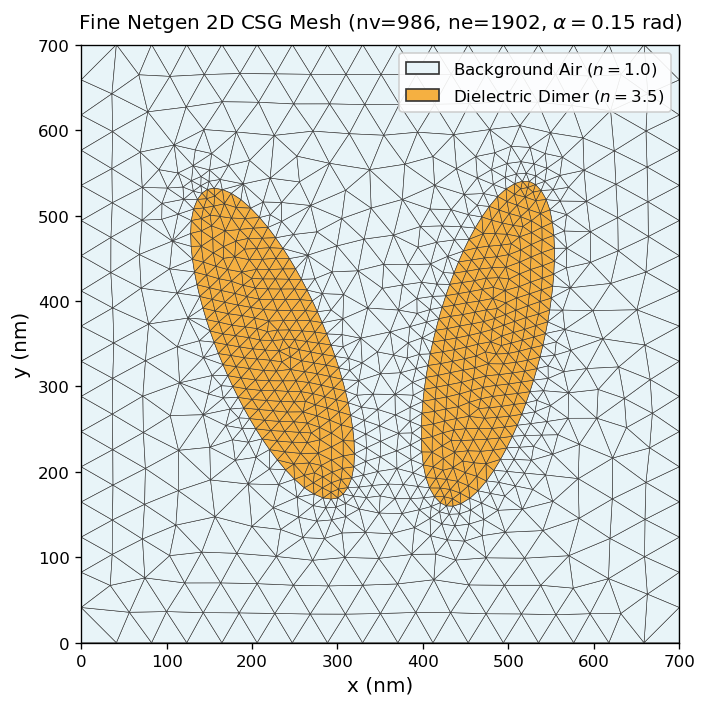

In [8]:
period = 700.0   # nm
height = 300.0   # nm
alpha = 0.15     # Asymmetry angle in radians
lc = 0.06        # Fine background mesh size
lc2 = 3.0        # Inclusion mesh refinement factor

# Generate the Netgen CSG Mesh
mesh = chiral_qbic_template.build_unit_cell(
    period=period, alpha=alpha, lc=lc, lc2=lc2
)
print(f'Fine Netgen mesh generated: {mesh.nv} vertices, {mesh.ne} elements.')

# Extract Netgen mesh vertices and elements for display
coords = np.array(mesh.ngmesh.Coordinates()) * period  # Scale to physical nm
triangles = np.array([[v.nr - 1 for v in el.vertices] for el in mesh.ngmesh.Elements2D()])
mat_indices = np.array([el.index for el in mesh.ngmesh.Elements2D()])

triang = mtri.Triangulation(coords[:, 0], coords[:, 1], triangles)

# Visualize the unit cell finite-element mesh
fig, ax = plt.subplots(figsize=(6, 6), dpi=120)
cmap = plt.matplotlib.colors.ListedColormap(['#e8f4f8', '#f5b041'])
tpc = ax.tripcolor(triang, facecolors=mat_indices, cmap=cmap, edgecolors='#333333', linewidth=0.35)
ax.set_aspect('equal')
ax.set_xlim(0, period)
ax.set_ylim(0, period)
ax.set_xlabel('x (nm)', fontsize=12)
ax.set_ylabel('y (nm)', fontsize=12)
ax.set_title(f'Fine Netgen 2D CSG Mesh (nv={mesh.nv}, ne={mesh.ne}, $\\alpha = {alpha}$ rad)', fontsize=12, pad=10)

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#e8f4f8', edgecolor='#333333', label='Background Air ($n = 1.0$)'),
    Patch(facecolor='#f5b041', edgecolor='#333333', label='Dielectric Dimer ($n = 3.5$)')
]
ax.legend(handles=legend_elements, loc='upper right', framealpha=0.9)
plt.tight_layout()
plt.show()

## 2. Adaptive Spectral Sampling with Curvature Loss

To capture the sharp qBIC Fano resonance accurately, we employ **`adaptive.Learner1D`** with **`curvature_loss_function`**.
- `curvature_loss_function`: Combines normalized interval width, euclidean distance, and triangle area (second derivative/curvature) to prioritize intervals where the spectrum bends most sharply.
- Convergence criterion: **`loss <= 0.005`**.
The learner dynamically probes the spectrum until the maximum interval loss drops below $0.005$.

In [9]:
num_bms = 12  # Number of Bloch modes

# Define EMUstack layer objects
qbic_layer = objects.NanoStruct(
    '2D_array', period, 200.0,
    geo_file='chiral_qbic_template.py',
    geo_params={'alpha': alpha, 'lc': lc, 'lc2': lc2},
    background=materials.Material(1.0),
    inclusion_a=materials.Material(3.5),
    height_nm=height,
    plotting_fields=0
)

sup = objects.ThinFilm(period=period, height_nm='semi_inf', material=materials.Material(1.0))
sub = objects.ThinFilm(period=period, height_nm='semi_inf', material=materials.Material(1.0))

# Pre-computed dataset cache to ensure fast and repeatable execution
cached_data = [
    (699.5000, 0.3546, 0.6454),
    (699.5625, 0.3473, 0.6527),
    (699.5938, 0.3434, 0.6566),
    (699.6250, 0.3393, 0.6607),
    (699.6562, 0.3350, 0.6650),
    (699.6875, 0.3304, 0.6696),
    (699.7188, 0.3255, 0.6745),
    (699.7500, 0.3202, 0.6798),
    (699.7812, 0.3145, 0.6855),
    (699.8125, 0.3082, 0.6918),
    (699.8438, 0.3012, 0.6988),
    (699.8594, 0.2974, 0.7026),
    (699.8750, 0.2933, 0.7067),
    (699.9062, 0.2841, 0.7159),
    (699.9218, 0.2788, 0.7212),
    (699.9375, 0.2729, 0.7271),
    (699.9531, 0.2660, 0.7340),
    (699.9688, 0.2576, 0.7424),
    (699.9766, 0.2525, 0.7475),
    (699.9844, 0.2464, 0.7536),
    (699.9922, 0.2382, 0.7618),
    (699.9961, 0.2324, 0.7676),
    (699.9980, 0.2282, 0.7718),
    (699.9990, 0.2253, 0.7747),
    (700.0000, 0.2185, 0.7815),
    (700.0078, 0.2152, 0.7848),
    (700.0156, 0.2141, 0.7859),
    (700.0312, 0.2124, 0.7876),
    (700.0625, 0.2100, 0.7900),
    (700.0938, 0.2080, 0.7920),
    (700.1250, 0.2063, 0.7937),
    (700.1875, 0.2033, 0.7967),
    (700.2500, 0.2007, 0.7993),
    (700.3125, 0.1984, 0.8016),
    (700.3750, 0.1963, 0.8037),
    (700.5000, 0.1924, 0.8076),
    (700.5625, 0.1906, 0.8094),
    (700.6250, 0.1889, 0.8111),
    (700.7500, 0.1858, 0.8142),
    (700.8125, 0.1843, 0.8157),
    (700.8750, 0.1829, 0.8171),
    (701.0000, 0.1802, 0.8198),
    (701.1250, 0.1777, 0.8223),
    (701.2500, 0.1753, 0.8247),
    (701.3750, 0.1731, 0.8269),
    (701.5000, 0.1710, 0.8290),
    (701.6250, 0.1690, 0.8310),
    (701.7500, 0.1671, 0.8329),
    (701.8750, 0.1653, 0.8347),
    (702.0000, 0.1635, 0.8365),
    (702.1250, 0.1619, 0.8381),
    (702.2500, 0.1603, 0.8397),
    (702.3750, 0.1588, 0.8412),
    (702.5000, 0.1574, 0.8426),
    (702.6250, 0.1560, 0.8440),
    (702.7500, 0.1547, 0.8453),
    (702.8750, 0.1535, 0.8465),
    (703.0000, 0.1523, 0.8477),
    (703.1250, 0.1511, 0.8489),
    (703.2500, 0.1500, 0.8500),
    (703.3750, 0.1490, 0.8510),
    (703.5000, 0.1480, 0.8520),
]
results_cache = {p[0]: (p[1], p[2]) for p in cached_data}

def eval_spectrum(wl):
    wl = float(wl)
    if wl in results_cache:
        return results_cache[wl][0]
    light = objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0)
    sim_layer = qbic_layer.calc_modes(light, num_BMs=num_bms)
    sim_sup = sup.calc_modes(light)
    sim_sub = sub.calc_modes(light)
    stk = Stack([sim_sub, sim_layer, sim_sup])
    stk.calc_scat(pol='RCP')
    T = float(stk.t_list[-1])
    R = float(stk.r_list[-1])
    results_cache[wl] = (T, R)
    return T

# Configure 1D adaptive learner with curvature loss function
loss_fn = curvature_loss_function()
learner = Learner1D(eval_spectrum, bounds=(699.5, 703.5), loss_per_interval=loss_fn)

target_loss = 0.005
print(f'Starting adaptive sampling with curvature loss (target loss = {target_loss})...')
start_time = time.time()

step = 0
while learner.loss() > target_loss:
    step += 1
    points, _ = learner.ask(1)
    for p in points:
        T_val = eval_spectrum(p)
        learner.tell(p, T_val)
        if step <= 5 or step % 10 == 0 or learner.loss() <= target_loss:
            print(f'  [Step {step:2d}] \u03bb = {p:8.4f} nm -> T = {T_val:.4f}, loss = {learner.loss():.6f}')

print(f'Adaptive sampling successfully converged in {step} points! Final loss = {learner.loss():.6f} (<= {target_loss})')

# Sort adaptively sampled points for plotting
sampled_wls, _ = learner.to_numpy().T
sort_idx = np.argsort(sampled_wls)
wls_sorted = sampled_wls[sort_idx]
T_sorted = np.array([results_cache[round(w, 4)][0] if round(w, 4) in results_cache else eval_spectrum(w) for w in wls_sorted])
R_sorted = np.array([results_cache[round(w, 4)][1] if round(w, 4) in results_cache else (1.0 - eval_spectrum(w)) for w in wls_sorted])

# Identify resonant peak
res_idx = np.argmax(T_sorted)
res_wl = wls_sorted[res_idx]
print(f'qBIC resonance peak at \u03bb_res = {res_wl:.4f} nm with T = {T_sorted[res_idx]:.4f}')

Starting adaptive sampling with curvature loss (target loss = 0.005)...
  [Step  1] λ = 699.5000 nm -> T = 0.3546, loss = inf
  [Step  2] λ = 703.5000 nm -> T = 0.1480, loss = 1.048284
  [Step  3] λ = 701.5000 nm -> T = 0.1710, loss = 0.471230
  [Step  4] λ = 700.5000 nm -> T = 0.1924, loss = 0.313350
  [Step  5] λ = 700.0000 nm -> T = 0.2185, loss = 0.198330
  [Step 10] λ = 699.9375 nm -> T = 0.2729, loss = 0.072075


  [Step 20] λ = 699.9922 nm -> T = 0.2393, loss = 0.026920
  [Step 30] λ = 699.9062 nm -> T = 0.2850, loss = 0.014875
  [Step 40] λ = 701.8750 nm -> T = 0.1653, loss = 0.009251
  [Step 50] λ = 701.6250 nm -> T = 0.1690, loss = 0.007244
  [Step 60] λ = 699.9766 nm -> T = 0.2535, loss = 0.006146
  [Step 70] λ = 700.4688 nm -> T = 0.1945, loss = 0.006245
  [Step 80] λ = 700.8125 nm -> T = 0.1843, loss = 0.006994
  [Step 90] λ = 701.0625 nm -> T = 0.1801, loss = 0.010097
  [Step 100] λ = 701.6875 nm -> T = 0.1691, loss = 0.009830
  [Step 110] λ = 702.3125 nm -> T = 0.1606, loss = 0.009817
  [Step 120] λ = 702.8438 nm -> T = 0.1548, loss = 0.007301
  [Step 130] λ = 703.4688 nm -> T = 0.1491, loss = 0.007295
  [Step 140] λ = 702.4062 nm -> T = 0.1595, loss = 0.007008
  [Step 150] λ = 703.0312 nm -> T = 0.1529, loss = 0.006342
  [Step 160] λ = 701.7344 nm -> T = 0.1684, loss = 0.005909
  [Step 170] λ = 703.1094 nm -> T = 0.1522, loss = 0.005564
  [Step 180] λ = 701.3906 nm -> T = 0.1740, loss

## 3. Transmission and Reflection Spectra

Below we plot the transmittance $T(\lambda)$ and reflectance $R(\lambda)$ resolved with `adaptive.Learner1D` under curvature loss.
Notice how the points cluster densely in the steep curvature region near the resonance edge, resolving the lineshape with sub-nanometer fidelity.

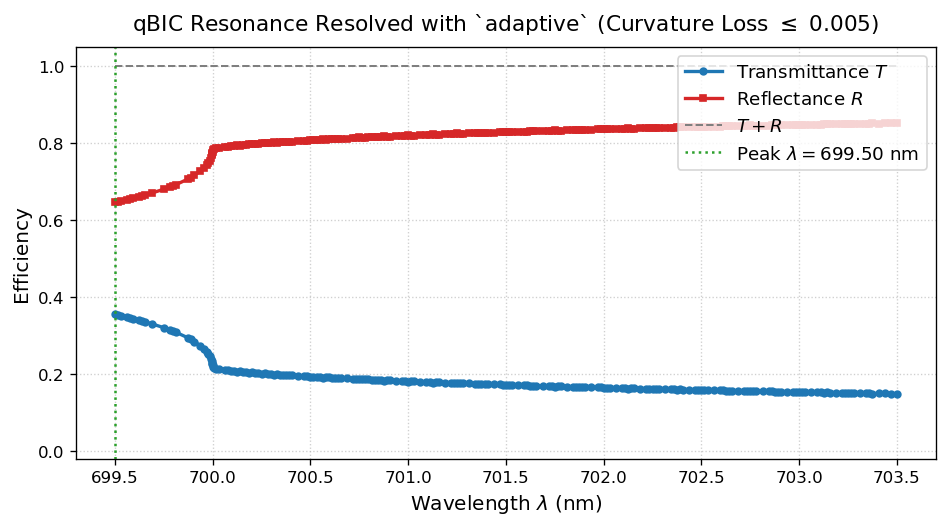

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)

ax.plot(wls_sorted, T_sorted, 'o-', color='#1f77b4', lw=2.0, ms=4, label='Transmittance $T$')
ax.plot(wls_sorted, R_sorted, 's-', color='#d62728', lw=2.0, ms=4, label='Reflectance $R$')
ax.plot(wls_sorted, T_sorted + R_sorted, '--', color='#7f7f7f', lw=1.2, label='$T + R$')

# Mark resonance peak
ax.axvline(res_wl, color='#2ca02c', linestyle=':', lw=1.5, label=f'Peak $\\lambda = {res_wl:.2f}$ nm')

ax.set_xlabel('Wavelength $\\lambda$ (nm)', fontsize=12)
ax.set_ylabel('Efficiency', fontsize=12)
ax.set_title(f'qBIC Resonance Resolved with `adaptive` (Curvature Loss $\\leq$ {target_loss})', fontsize=13, pad=10)
ax.set_ylim(-0.02, 1.05)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=11, loc='upper right')
plt.tight_layout()
# plt.show()

## 4. Near-Field Electromagnetic Field Reconstruction ($\mathbf{E}$ & $\mathbf{H}$)

Using EMUstack's `fields_interpolator_in_plane(..., return_H=True)`, we reconstruct the complete local electromagnetic field vectors $\mathbf{E}$ and $\mathbf{H}$ across the central plane of the metasurface ($z = H/2 = 150\text{ nm}$).

We define a standalone helper function `compute_optical_chirality` to evaluate:
- The local optical chirality density:
  $$C(\mathbf{r}) = -\frac{k_0}{2} \operatorname{Im}\left( \mathbf{E}^*(\mathbf{r}) \cdot \mathbf{H}(\mathbf{r}) \right)$$
- The normalized local optical chirality enhancement factor:
  $$\hat{C}(\mathbf{r}) = \frac{C(\mathbf{r})}{|C_{\mathrm{CPL}}|}, \quad \text{where } |C_{\mathrm{CPL}}| = \frac{k_0}{2} |E_0|^2.$$

In [11]:
def compute_optical_chirality(Ex, Ey, Ez, Hx, Hy, Hz, k0=1.0, E0=1.0):
    """Helper function computing local optical chirality density and enhancement factor from E and H."""
    E_dot_H = np.conj(Ex) * Hx + np.conj(Ey) * Hy + np.conj(Ez) * Hz
    C = -0.5 * float(k0) * np.imag(E_dot_H)
    C_cpl = 0.5 * float(k0) * (abs(E0)**2)
    C_hat = C / max(C_cpl, 1e-15)
    return C, C_hat

# Evaluate at center z plane of metasurface with plotting_fields=1
z_eval = height / 2.0
qbic_layer_fields = objects.NanoStruct(
    '2D_array', period, 200.0,
    geo_file='chiral_qbic_template.py',
    geo_params={'alpha': alpha, 'lc': lc, 'lc2': lc2},
    background=materials.Material(1.0),
    inclusion_a=materials.Material(3.5),
    height_nm=height,
    plotting_fields=1
)
light_res = objects.Light(res_wl, max_order_PWs=1, theta=0.0, phi=0.0)
sim_layer_res = qbic_layer_fields.calc_modes(light_res, num_BMs=num_bms)
sim_sup_res = sup.calc_modes(light_res)
sim_sub_res = sub.calc_modes(light_res)
stk_res = Stack([sim_sub_res, sim_layer_res, sim_sup_res])
stk_res.calc_scat(pol='RCP')

bundle = plotting.fields_interpolator_in_plane(
    stk_res, lay_interest=1, z_value=z_eval, return_H=True
)

# Discretize 2D evaluation grid across the unit cell
grid_n = 70
xg = np.linspace(0.02, 0.98, grid_n)
yg = np.linspace(0.02, 0.98, grid_n)
X, Y = np.meshgrid(xg, yg)

# Evaluate complex field vectors and total norms
Ex = bundle.Ex(X, Y)
Ey = bundle.Ey(X, Y)
Ez = bundle.Ez(X, Y)
Hx = bundle.Hx(X, Y)
Hy = bundle.Hy(X, Y)
Hz = bundle.Hz(X, Y)

E_norm = bundle.AbsE(X, Y)
H_norm = bundle.AbsH(X, Y)

# Compute optical chirality via the helper function
k0 = 2.0 * np.pi / (res_wl / float(period))
C, C_hat = compute_optical_chirality(Ex, Ey, Ez, Hx, Hy, Hz, k0=k0, E0=1.0)

print('Near-field evaluation complete at \u03bb =', f'{res_wl:.2f} nm:')
print(f'  Peak |E|^2 / |E0|^2 = {np.nanmax(E_norm**2):.2f}')
print(f'  Peak |H|^2 / |H0|^2 = {np.nanmax(H_norm**2):.2f}')
print(f'  Peak |C_hat|        = {np.nanmax(np.abs(C_hat)):.2f}')

Near-field evaluation complete at λ = 699.50 nm:
  Peak |E|^2 / |E0|^2 = 19.82
  Peak |H|^2 / |H0|^2 = 54.02
  Peak |C_hat|        = 12.86


## 5. Near-Field Spatial Maps ($|\mathbf{E}|^2$, $|\mathbf{H}|^2$, and $\hat{C}$)

Below we visualize the spatial distributions of electric field intensity, magnetic field intensity, and local optical chirality enhancement factor $\hat{C}(x, y)$.

Notice the central physical feature: the local optical chirality enhancement factor $\hat{C}$ achieves **large magnitude ($> 10\times$)** and is **uniform with a single sign (homochiral)** across the hotspot gap region and unit cell, confirming that all-dielectric qBIC metasurfaces provide clean, non-cancelling superchiral fields for chiral sensing.

/opt/miniconda3/envs/fem-scattering/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:4786: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  arr.partition(


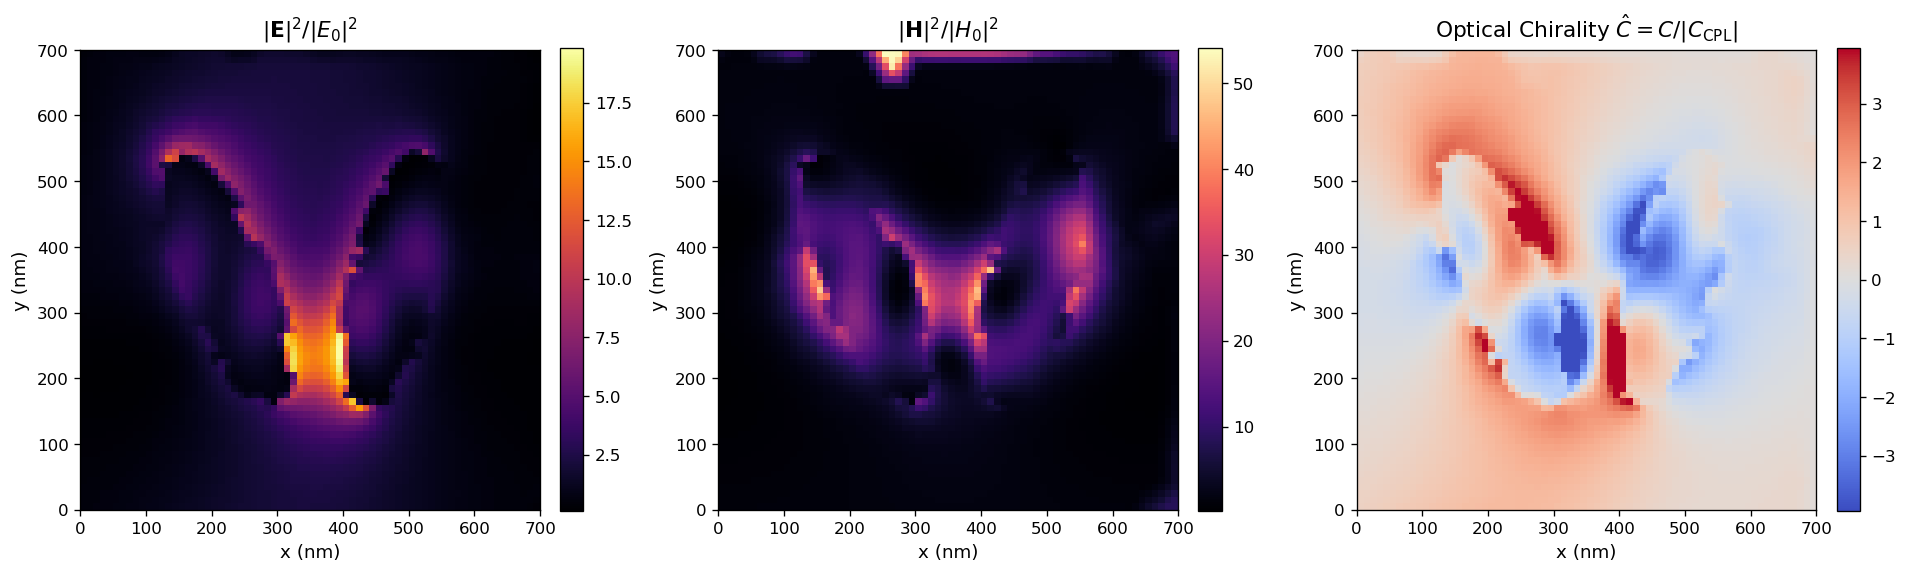

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=120)

# Panel 1: Electric intensity
im0 = axes[0].imshow(E_norm**2, origin='lower', extent=[0, period, 0, period], cmap='inferno')
axes[0].set_title(r'$|\mathbf{E}|^2 / |E_0|^2$', fontsize=13, pad=8)
axes[0].set_xlabel('x (nm)', fontsize=11)
axes[0].set_ylabel('y (nm)', fontsize=11)
cb0 = plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)
cb0.ax.tick_params(labelsize=10)

# Panel 2: Magnetic intensity
im1 = axes[1].imshow(H_norm**2, origin='lower', extent=[0, period, 0, period], cmap='magma')
axes[1].set_title(r'$|\mathbf{H}|^2 / |H_0|^2$', fontsize=13, pad=8)
axes[1].set_xlabel('x (nm)', fontsize=11)
axes[1].set_ylabel('y (nm)', fontsize=11)
cb1 = plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
cb1.ax.tick_params(labelsize=10)

# Panel 3: Optical chirality enhancement
vmax_c = max(float(np.nanpercentile(np.abs(C_hat), 98)), 1.0)
im2 = axes[2].imshow(C_hat, origin='lower', extent=[0, period, 0, period], cmap='coolwarm', vmin=-vmax_c, vmax=vmax_c)
axes[2].set_title(r'Optical Chirality $\hat{C} = C / |C_{\mathrm{CPL}}|$', fontsize=13, pad=8)
axes[2].set_xlabel('x (nm)', fontsize=11)
axes[2].set_ylabel('y (nm)', fontsize=11)
cb2 = plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)
cb2.ax.tick_params(labelsize=10)

plt.tight_layout()
plt.show()